# 02 Exploratory Data Analysis: Attenomy telemetry dataset
Target: `is_anomaly`. All figures use the **training split only** (70%, seed 42, stratified), so no choice about features or charts is influenced by validation or test rows.

## Part 1: 8 figures
Each figure is saved to `reports/figures/` and has a title, axis labels with units, a legend and a one-sentence takeaway caption. The captions are computed from the data, so they always match the chart.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.utils import train_val_test_split  # noqa: E402

CLEAN = ROOT / "data" / "clean" / "clean.parquet"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
NORMAL, ANOMALY = "#4C78A8", "#E45756"

In [2]:
clean_df = pd.read_parquet(CLEAN)
train, _, _ = train_val_test_split(
    clean_df, (0.7, 0.15, 0.15), seed=42, stratify_col="is_anomaly"
)
normal = train[train["is_anomaly"] == 0]
anomal = train[train["is_anomaly"] == 1]
overall = train["is_anomaly"].mean()
print(f"Training rows: {len(train):,} | normal: {len(normal):,} | anomaly: {len(anomal):,}")
print(f"Overall anomaly rate: {overall:.2%}")


def finish(fig, name, caption):
    """Add the takeaway caption under the figure, save it as a PNG and show it."""
    fig.text(
        0.5,
        -0.01,
        textwrap.fill(caption, 110),
        ha="center",
        va="top",
        fontsize=9,
        style="italic",
    )
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{name}: {caption}")

Training rows: 17,500 | normal: 16,815 | anomaly: 685
Overall anomaly rate: 3.91%


### Figure 1: Feature distributions

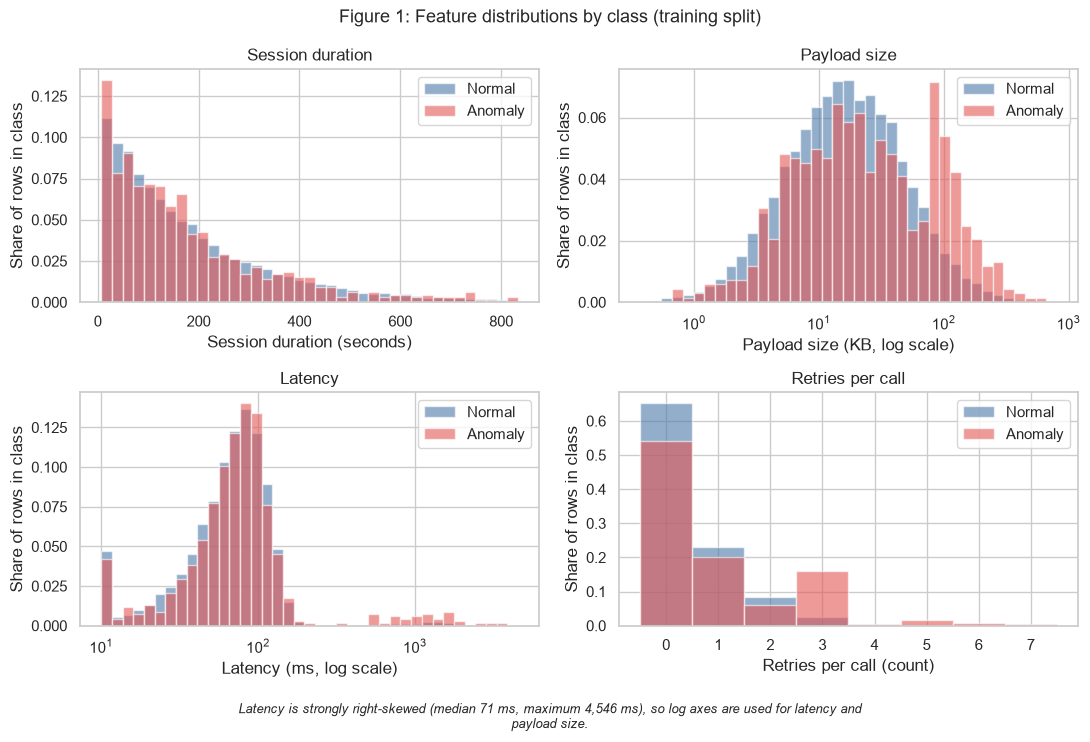

fig1_feature_distributions.png: Latency is strongly right-skewed (median 71 ms, maximum 4,546 ms), so log axes are used for latency and payload size.


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
specs = [
    ("session_duration_sec", "Session duration (seconds)", False),
    ("payload_size_kb", "Payload size (KB, log scale)", True),
    ("latency_ms", "Latency (ms, log scale)", True),
    ("retry_count", "Retries per call (count)", False),
]
for ax, (col, label, log) in zip(axes.ravel(), specs):
    values = train[col].dropna()
    if col == "retry_count":
        bins = np.arange(-0.5, values.max() + 1.5, 1)
    elif log:
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 40)
    else:
        bins = np.linspace(values.min(), values.max(), 40)
    for data, color, name in ((normal, NORMAL, "Normal"), (anomal, ANOMALY, "Anomaly")):
        x = data[col].dropna()
        ax.hist(
            x,
            bins=bins,
            weights=np.ones(len(x)) / len(x),
            alpha=0.6,
            color=color,
            label=name,
        )
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Share of rows in class")
    ax.set_title(label.split(" (")[0])
    ax.legend()
fig.suptitle("Figure 1: Feature distributions by class (training split)", fontsize=13)
fig.tight_layout()
lat = train["latency_ms"]
finish(
    fig,
    "fig1_feature_distributions.png",
    f"Latency is strongly right-skewed (median {lat.median():.0f} ms, maximum "
    f"{lat.max():,.0f} ms), so log axes are used for latency and payload size.",
)

### Figure 2: Target balance

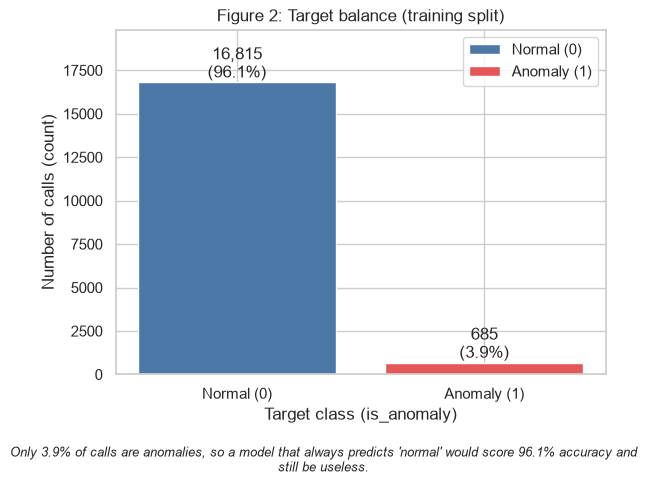

fig2_target_balance.png: Only 3.9% of calls are anomalies, so a model that always predicts 'normal' would score 96.1% accuracy and still be useless.


In [4]:
counts = train["is_anomaly"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, color, name in ((0, NORMAL, "Normal (0)"), (1, ANOMALY, "Anomaly (1)")):
    ax.bar(name, counts[cls], color=color, label=name)
    ax.text(
        name,
        counts[cls],
        f"{counts[cls]:,}\n({counts[cls] / len(train):.1%})",
        ha="center",
        va="bottom",
    )
ax.set_ylim(0, counts.max() * 1.18)
ax.set_xlabel("Target class (is_anomaly)")
ax.set_ylabel("Number of calls (count)")
ax.set_title("Figure 2: Target balance (training split)")
ax.legend()
fig.tight_layout()
finish(
    fig,
    "fig2_target_balance.png",
    f"Only {overall:.1%} of calls are anomalies, so a model that always predicts "
    f"'normal' would score {1 - overall:.1%} accuracy and still be useless.",
)

### Figure 3: Correlation heatmap
Spearman (rank) correlation is used because the numeric features are skewed.

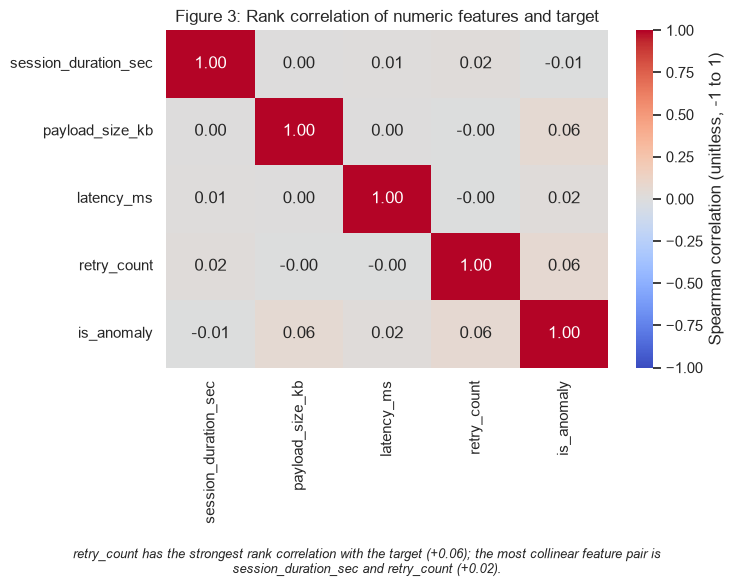

fig3_correlation_heatmap.png: retry_count has the strongest rank correlation with the target (+0.06); the most collinear feature pair is session_duration_sec and retry_count (+0.02).


In [5]:
corr_cols = [
    "session_duration_sec",
    "payload_size_kb",
    "latency_ms",
    "retry_count",
    "is_anomaly",
]
corr = train[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax,
    cbar_kws={"label": "Spearman correlation (unitless, -1 to 1)"},
)
ax.set_title("Figure 3: Rank correlation of numeric features and target")
fig.tight_layout()

target_corr = corr["is_anomaly"].drop("is_anomaly")
top_feature = target_corr.abs().idxmax()
feats = corr.drop(index="is_anomaly", columns="is_anomaly")
names = list(feats.columns)
best = max(
    ((a, b) for i, a in enumerate(names) for b in names[i + 1 :]),
    key=lambda p: abs(feats.loc[p[0], p[1]]),
)
finish(
    fig,
    "fig3_correlation_heatmap.png",
    f"{top_feature} has the strongest rank correlation with the target "
    f"({target_corr[top_feature]:+.2f}); the most collinear feature pair is "
    f"{best[0]} and {best[1]} ({feats.loc[best[0], best[1]]:+.2f}).",
)

### Figure 4: Anomaly rate by error code

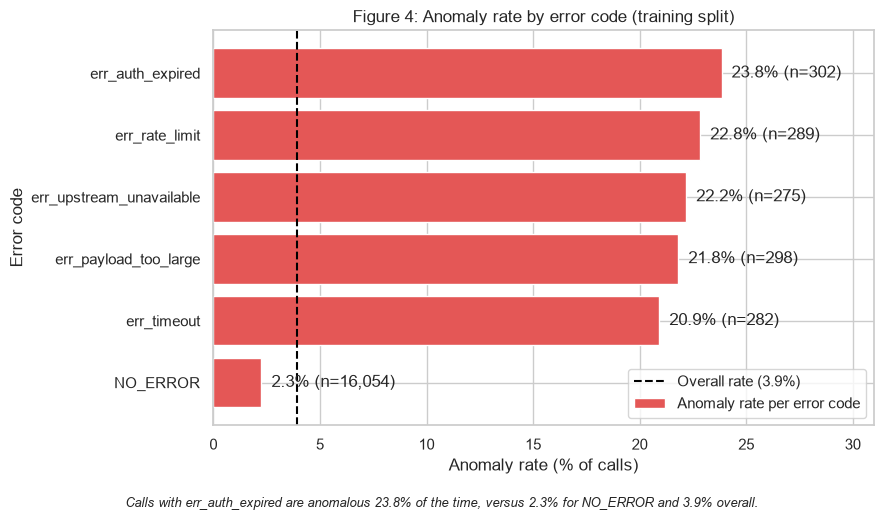

fig4_anomaly_by_error_code.png: Calls with err_auth_expired are anomalous 23.8% of the time, versus 2.3% for NO_ERROR and 3.9% overall.


In [6]:
err_stats = (
    train.groupby("error_code", observed=True)["is_anomaly"]
    .agg(["mean", "size"])
    .sort_values("mean")
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    err_stats.index.astype(str),
    err_stats["mean"] * 100,
    color=ANOMALY,
    label="Anomaly rate per error code",
)
for y, (rate, n) in enumerate(zip(err_stats["mean"], err_stats["size"])):
    ax.text(rate * 100, y, f"  {rate:.1%} (n={n:,})", va="center")
ax.axvline(overall * 100, color="black", linestyle="--", label=f"Overall rate ({overall:.1%})")
ax.set_xlim(0, err_stats["mean"].max() * 100 * 1.3)
ax.set_xlabel("Anomaly rate (% of calls)")
ax.set_ylabel("Error code")
ax.set_title("Figure 4: Anomaly rate by error code (training split)")
ax.legend(loc="lower right")
fig.tight_layout()
high, low = err_stats["mean"].idxmax(), err_stats["mean"].idxmin()
finish(
    fig,
    "fig4_anomaly_by_error_code.png",
    f"Calls with {high} are anomalous {err_stats.loc[high, 'mean']:.1%} of the time, versus "
    f"{err_stats.loc[low, 'mean']:.1%} for {low} and {overall:.1%} overall.",
)

### Figure 5: Anomaly rate by client tier and channel

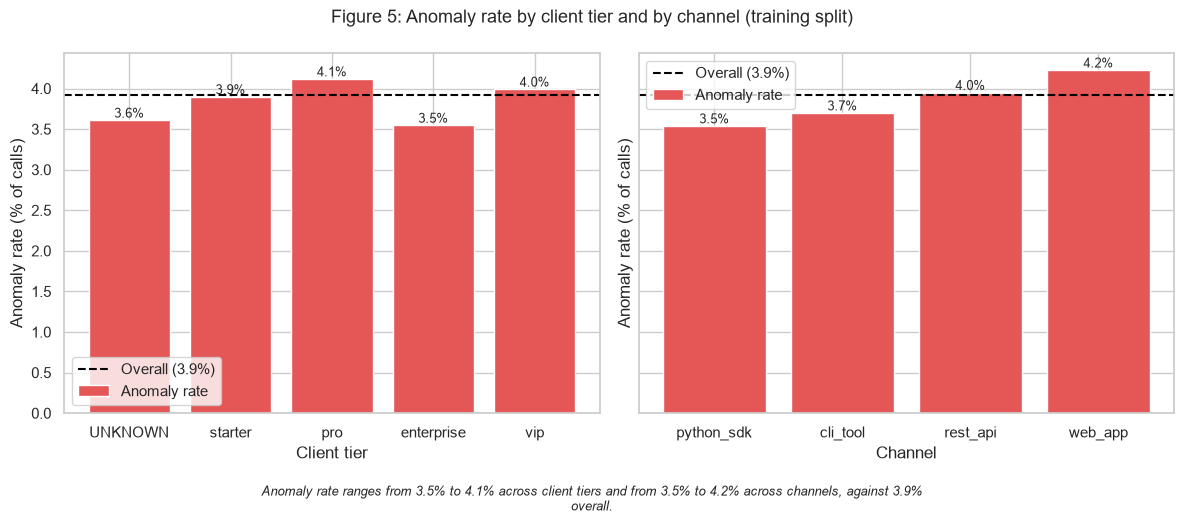

fig5_anomaly_by_tier_channel.png: Anomaly rate ranges from 3.5% to 4.1% across client tiers and from 3.5% to 4.2% across channels, against 3.9% overall.


In [7]:
tier_order = ["UNKNOWN", "starter", "pro", "enterprise", "vip"]
by_tier = (
    train.groupby("client_tier", observed=True)["is_anomaly"].mean().reindex(tier_order) * 100
)
by_channel = train.groupby("channel", observed=True)["is_anomaly"].mean().sort_values() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
panels = [
    (axes[0], tier_order, by_tier.to_numpy(), "Client tier"),
    (axes[1], [str(c) for c in by_channel.index], by_channel.to_numpy(), "Channel"),
]
for ax, labels, values, xlabel in panels:
    ax.bar(labels, values, color=ANOMALY, label="Anomaly rate")
    for x, v in zip(labels, values):
        ax.text(x, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.axhline(overall * 100, color="black", linestyle="--", label=f"Overall ({overall:.1%})")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Anomaly rate (% of calls)")
    ax.legend()
fig.suptitle("Figure 5: Anomaly rate by client tier and by channel (training split)", fontsize=13)
fig.tight_layout()
finish(
    fig,
    "fig5_anomaly_by_tier_channel.png",
    f"Anomaly rate ranges from {np.nanmin(by_tier):.1f}% to {np.nanmax(by_tier):.1f}% "
    f"across client tiers and from {by_channel.min():.1f}% to {by_channel.max():.1f}% "
    f"across channels, against {overall:.1%} overall.",
)

### Figure 6: Latency and session duration, normal vs anomaly
Empirical cumulative distribution (ECDF): the further right a curve sits, the larger the values in that class.

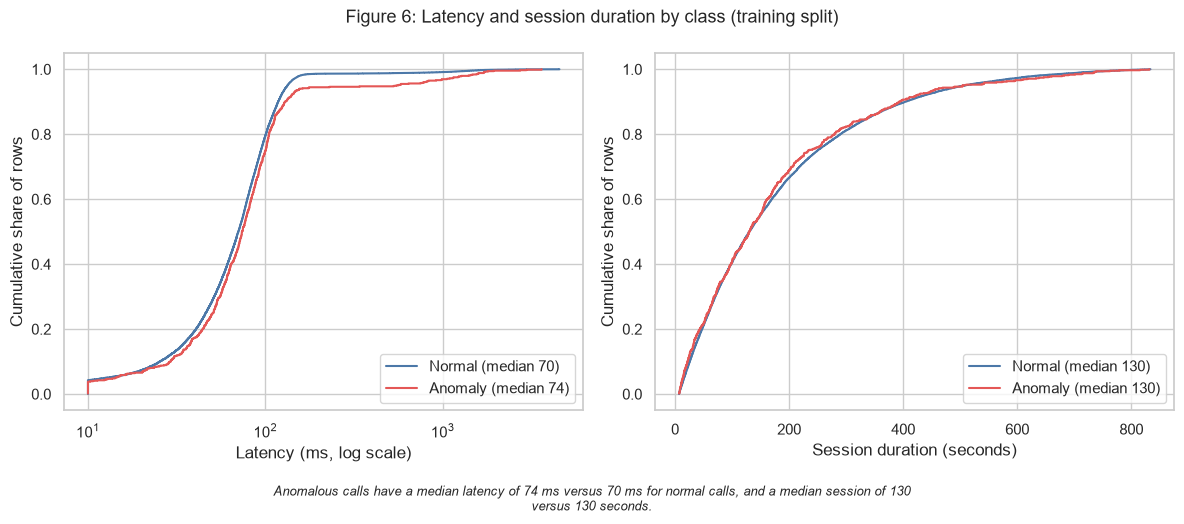

fig6_numeric_vs_target.png: Anomalous calls have a median latency of 74 ms versus 70 ms for normal calls, and a median session of 130 versus 130 seconds.


In [8]:
def ecdf(series):
    """Return sorted values and their cumulative share, ignoring missing values."""
    x = np.sort(series.dropna().to_numpy())
    return x, np.arange(1, len(x) + 1) / len(x)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ecdf_specs = [
    ("latency_ms", "Latency (ms, log scale)", True),
    ("session_duration_sec", "Session duration (seconds)", False),
]
for ax, (col, label, log) in zip(axes, ecdf_specs):
    for data, color, name in ((normal, NORMAL, "Normal"), (anomal, ANOMALY, "Anomaly")):
        x, y = ecdf(data[col])
        ax.step(x, y, where="post", color=color, label=f"{name} (median {np.median(x):,.0f})")
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Cumulative share of rows")
    ax.legend(loc="lower right")
fig.suptitle("Figure 6: Latency and session duration by class (training split)", fontsize=13)
fig.tight_layout()
finish(
    fig,
    "fig6_numeric_vs_target.png",
    f"Anomalous calls have a median latency of {anomal['latency_ms'].median():.0f} ms "
    f"versus {normal['latency_ms'].median():.0f} ms for normal calls, and a median session "
    f"of {anomal['session_duration_sec'].median():.0f} versus "
    f"{normal['session_duration_sec'].median():.0f} seconds.",
)

### Figure 7: Latency outliers across subgroups

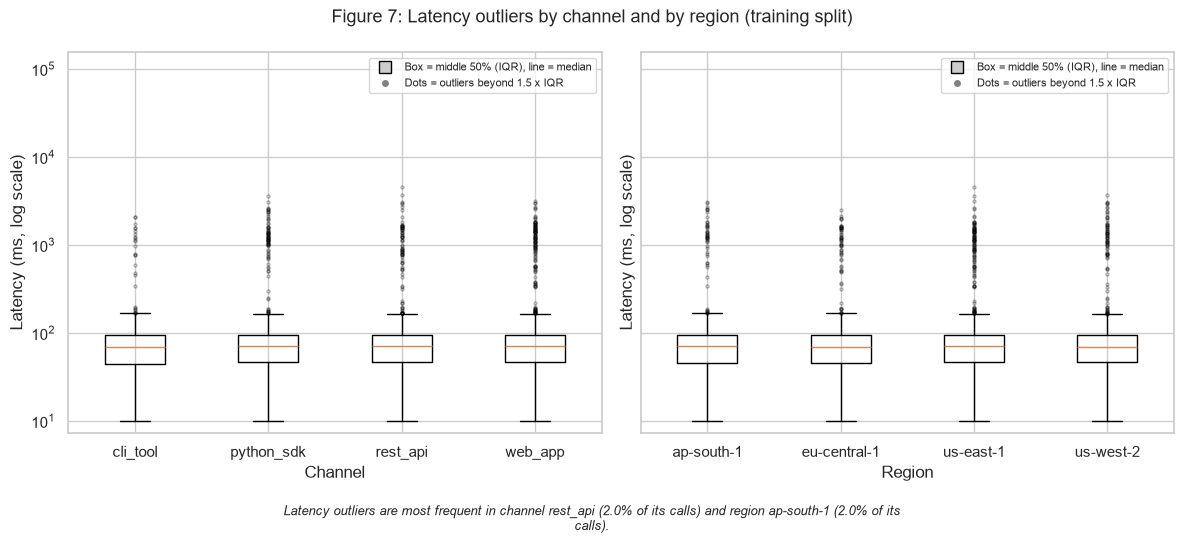

fig7_latency_outliers_by_subgroup.png: Latency outliers are most frequent in channel rest_api (2.0% of its calls) and region ap-south-1 (2.0% of its calls).


In [9]:
legend_handles = [
    Line2D(
        [0], [0], marker="s", color="w", markerfacecolor="#cccccc",
        markeredgecolor="black", markersize=9, label="Box = middle 50% (IQR), line = median",
    ),
    Line2D(
        [0], [0], marker="o", color="w", markerfacecolor="gray",
        markersize=6, label="Dots = outliers beyond 1.5 x IQR",
    ),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, group in zip(axes, ["channel", "region"]):
    labels = sorted(train[group].astype(str).unique())
    data = [train.loc[train[group].astype(str) == g, "latency_ms"] for g in labels]
    ax.boxplot(data, flierprops={"marker": "o", "markersize": 2, "alpha": 0.3})
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels)
    ax.set_yscale("log")
    ax.set_xlabel(group.capitalize())
    ax.set_ylabel("Latency (ms, log scale)")
    low, high = ax.get_ylim()
    ax.set_ylim(low, high * 5)
    ax.legend(handles=legend_handles, loc="upper right", fontsize=8)
fig.suptitle("Figure 7: Latency outliers by channel and by region (training split)", fontsize=13)
fig.tight_layout()
share_ch = train.groupby("channel", observed=True)["latency_ms_is_outlier"].mean()
share_rg = train.groupby("region", observed=True)["latency_ms_is_outlier"].mean()
finish(
    fig,
    "fig7_latency_outliers_by_subgroup.png",
    f"Latency outliers are most frequent in channel {share_ch.idxmax()} "
    f"({share_ch.max():.1%} of its calls) and region {share_rg.idxmax()} "
    f"({share_rg.max():.1%} of its calls).",
)

### Figure 8: Interaction heatmap (channel x interaction type)

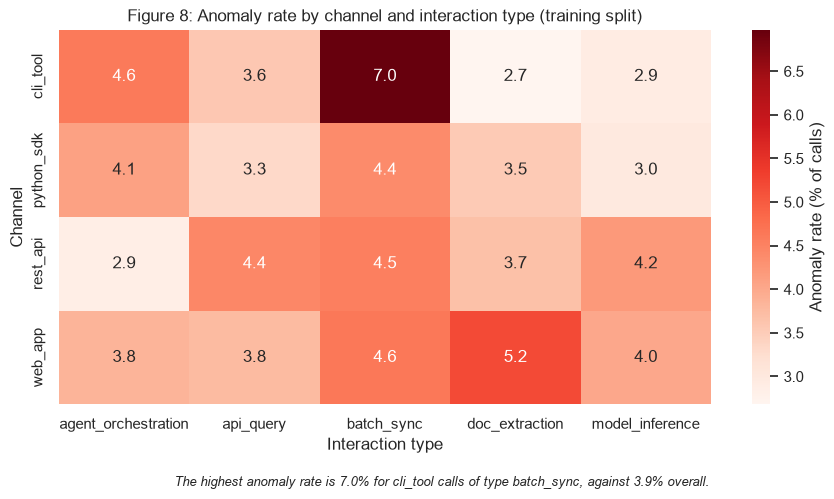

fig8_channel_interaction_heatmap.png: The highest anomaly rate is 7.0% for cli_tool calls of type batch_sync, against 3.9% overall.


In [10]:
grid = (
    train.groupby(["channel", "interaction_type"], observed=True)["is_anomaly"]
    .mean()
    .unstack()
    * 100
)
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(
    grid,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    ax=ax,
    cbar_kws={"label": "Anomaly rate (% of calls)"},
)
ax.set_xlabel("Interaction type")
ax.set_ylabel("Channel")
ax.set_title("Figure 8: Anomaly rate by channel and interaction type (training split)")
fig.tight_layout()
flat = grid.to_numpy()
i, j = np.unravel_index(np.nanargmax(flat), flat.shape)
finish(
    fig,
    "fig8_channel_interaction_heatmap.png",
    f"The highest anomaly rate is {flat[i, j]:.1f}% for {grid.index[i]} calls of type "
    f"{grid.columns[j]}, against {overall * 100:.1f}% overall.",
)

In [11]:
files = sorted(p.name for p in FIG_DIR.glob("fig*.png"))
print(f"{len(files)} figures saved in {FIG_DIR}:")
for name in files:
    print(" -", name)
assert len(files) == 8, "Expected exactly 8 figures"

8 figures saved in d:\ml-engineer-internship\reports\figures:
 - fig1_feature_distributions.png
 - fig2_target_balance.png
 - fig3_correlation_heatmap.png
 - fig4_anomaly_by_error_code.png
 - fig5_anomaly_by_tier_channel.png
 - fig6_numeric_vs_target.png
 - fig7_latency_outliers_by_subgroup.png
 - fig8_channel_interaction_heatmap.png


## Part 2: Hypotheses and statistical tests
Five hypotheses, written before looking at test results. All tests use the **training split only**. Because five tests are run on one dataset, the decision threshold is adjusted with a Bonferroni correction (0.05 / 5 = 0.01) so that a lucky result is less likely to be reported as real.

| # | Hypothesis | Test |
|---|---|---|
| H1 | The anomaly rate depends on `error_code` | Chi-square test of independence |
| H2 | Anomalous calls have a different `latency_ms` distribution | Mann-Whitney U (two-sided) |
| H3 | The anomaly rate depends on `client_tier` | Chi-square test of independence |
| H4 | Anomalous sessions have a different `session_duration_sec` distribution | Mann-Whitney U (two-sided) |
| H5 | Anomalous calls have more `retry_count` than normal calls | Mann-Whitney U (one-sided, anomaly greater) |

**Why these tests.** Chi-square compares a categorical feature with the binary label. Latency and session duration are strongly right-skewed (checked below), so a t-test, which assumes roughly normal data, is not appropriate. Mann-Whitney U compares ranks, so it does not assume normality and is not distorted by extreme outliers.

In [12]:
ALPHA = 0.05
N_TESTS = 5
ALPHA_ADJ = ALPHA / N_TESTS
results = []

print("Skewness (0 = symmetric, above 1 = strongly right-skewed):")
for col in ["latency_ms", "session_duration_sec", "payload_size_kb", "retry_count"]:
    print(f"  {col}: {train[col].skew():.2f}")


def fmt_p(p):
    """Format a p-value, avoiding a misleading 0.0."""
    return "< 1e-300" if p < 1e-300 else f"{p:.3g}"


def effect_word(v):
    """Plain-language size of a Cramer's V effect."""
    return "negligible" if v < 0.1 else "small" if v < 0.3 else "medium" if v < 0.5 else "large"


def chi2_test(tag, col):
    """Chi-square test of independence between a categorical column and is_anomaly."""
    table = pd.crosstab(train[col].astype(str), train["is_anomaly"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    v = float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))
    rates = table[1] / table.sum(axis=1)
    reject = p < ALPHA_ADJ
    if reject:
        meaning = (
            f"Reject H0: the anomaly rate depends on {col}. It is highest for "
            f"{rates.idxmax()} ({rates.max():.1%}) and lowest for {rates.idxmin()} "
            f"({rates.min():.1%}); the effect is {effect_word(v)} (Cramer's V = {v:.2f})."
        )
    else:
        meaning = (
            f"Fail to reject H0: no reliable evidence that the anomaly rate depends on {col} "
            f"(rates range from {rates.min():.1%} to {rates.max():.1%})."
        )
    print(f"{tag}: {col} vs is_anomaly (chi-square test of independence)")
    print(f"  H0: {col} and is_anomaly are independent")
    print(f"  chi2 = {chi2:.2f} | dof = {dof} | p-value = {fmt_p(p)} | Cramer's V = {v:.3f}")
    print(f"  smallest expected count = {expected.min():.1f} (assumption: at least 5)")
    print(f"  Interpretation: {meaning}")
    print(table.assign(anomaly_rate_pct=(rates * 100).round(2)).to_string(), "\n")
    results.append(
        {
            "hypothesis": tag, "feature": col, "test": "chi-square",
            "statistic": round(float(chi2), 2), "dof": int(dof), "p_value": fmt_p(p),
            "effect_size": f"Cramer's V = {v:.3f}", "reject_H0": bool(reject),
        }
    )


def mwu_test(tag, col, alternative="two-sided"):
    """Mann-Whitney U test of a numeric column between anomalous and normal rows."""
    a = anomal[col].dropna()
    b = normal[col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative=alternative)
    auc = float(u / (len(a) * len(b)))
    reject = p < ALPHA_ADJ
    direction = "higher" if a.median() > b.median() else "lower"
    if reject:
        meaning = (
            f"Reject H0: anomalous calls have {direction} {col} (median {a.median():.1f} vs "
            f"{b.median():.1f}). A random anomalous call exceeds a random normal call "
            f"{auc:.0%} of the time."
        )
    else:
        meaning = (
            f"Fail to reject H0: no reliable difference in {col} between classes "
            f"(median {a.median():.1f} vs {b.median():.1f})."
        )
    leak = " WARNING: near-perfect separation, check for label leakage." if auc > 0.95 or auc < 0.05 else ""
    h0 = "anomaly and normal rows share the same distribution of " + col
    if alternative == "greater":
        h0 = f"{col} is not larger for anomalous rows than for normal rows"
    print(f"{tag}: {col} vs is_anomaly (Mann-Whitney U, {alternative})")
    print(f"  H0: {h0}")
    print(f"  U = {u:,.0f} | dof = N/A (non-parametric) | p-value = {fmt_p(p)}")
    print(f"  group sizes: anomaly n = {len(a):,}, normal n = {len(b):,} (missing values dropped)")
    print(f"  Interpretation: {meaning}{leak}\n")
    results.append(
        {
            "hypothesis": tag, "feature": col, "test": f"Mann-Whitney U ({alternative})",
            "statistic": round(float(u)), "dof": "N/A", "p_value": fmt_p(p),
            "effect_size": f"AUC = {auc:.3f}", "reject_H0": bool(reject),
        }
    )

Skewness (0 = symmetric, above 1 = strongly right-skewed):
  latency_ms: 10.90
  session_duration_sec: 1.42
  payload_size_kb: 5.23
  retry_count: 2.49


### Run the five tests

In [13]:
chi2_test("H1", "error_code")
mwu_test("H2", "latency_ms")
chi2_test("H3", "client_tier")
mwu_test("H4", "session_duration_sec")
mwu_test("H5", "retry_count", alternative="greater")

H1: error_code vs is_anomaly (chi-square test of independence)
  H0: error_code and is_anomaly are independent
  chi2 = 1426.21 | dof = 5 | p-value = < 1e-300 | Cramer's V = 0.285
  smallest expected count = 10.8 (assumption: at least 5)
  Interpretation: Reject H0: the anomaly rate depends on error_code. It is highest for err_auth_expired (23.8%) and lowest for NO_ERROR (2.3%); the effect is small (Cramer's V = 0.29).
is_anomaly                    0    1  anomaly_rate_pct
error_code                                            
NO_ERROR                  15692  362              2.25
err_auth_expired            230   72             23.84
err_payload_too_large       233   65             21.81
err_rate_limit              223   66             22.84
err_timeout                 223   59             20.92
err_upstream_unavailable    214   61             22.18 

H2: latency_ms vs is_anomaly (Mann-Whitney U, two-sided)
  H0: anomaly and normal rows share the same distribution of latency_ms
  U = 

### Results summary

In [14]:
summary = pd.DataFrame(results)
summary.to_csv(ROOT / "reports" / "hypothesis_results.csv", index=False)
print(f"Decision threshold per test (Bonferroni): {ALPHA_ADJ:.3f}")
summary

Decision threshold per test (Bonferroni): 0.010


,hypothesis,feature,test,statistic,dof,p_value,effect_size,reject_H0
0,H1,error_code,chi-square,1426.21,5,< 1e-300,Cramer's V = 0.285,True
1,H2,latency_ms,Mann-Whitney U (two-sided),6146454.00,N/A,0.0028,AUC = 0.534,True
2,H3,client_tier,chi-square,1.75,4,0.782,Cramer's V = 0.010,False
3,H4,session_duration_sec,Mann-Whitney U (two-sided),5163200.00,N/A,0.392,AUC = 0.490,False
4,H5,retry_count,Mann-Whitney U (greater),6679158.00,N/A,2.5e-17,AUC = 0.580,True


## Assumptions and caveats (for the review)
- **Chi-square** assumes independent rows and expected counts of at least 5 in the cells. The smallest expected count is printed for each test. It shows association, not causation.
- **Mann-Whitney U** assumes independent samples. It compares ranks, so skew and extreme outliers do not distort it. It does not assume normality, which is why it is used instead of a t-test. Rows with missing values are dropped for that test only, and the group sizes are printed.
- **Large samples make tiny effects significant.** That is why every test also reports an effect size (Cramer's V or AUC), and the interpretation uses it.
- **Multiple tests.** The Bonferroni threshold of 0.01 guards against false positives from running five tests.
- **Label leakage screen.** An AUC close to 0 or 1 would mean one feature almost determines the label, which the notebook flags with a warning.